# Data Analysis of the tables

We need to perform data analysis of tables to check for NaN on numerical/integer fields and empty strings in columns

In [38]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

## Adding df.describe() of each table to detect which columns have NaNs

In [39]:
DATA_PATH = "data"
RESULTS_PATH = "data_analysis"
DESCRIBES_PATH = os.path.join(RESULTS_PATH, "describes")
os.makedirs(DESCRIBES_PATH, exist_ok=True)

# Load every CSV once into a dict: {"teams": DataFrame, "goalies": DataFrame, ...}
tables = {}
for entry in sorted(os.scandir(DATA_PATH), key=lambda e: e.name):
    if entry.is_file() and entry.name.endswith(".csv"):
        name = os.path.splitext(entry.name)[0]
        tables[name] = pd.read_csv(entry.path)

for name, df in tables.items():
    df.describe(include="all").to_csv(os.path.join(DESCRIBES_PATH, f"{name}_describe.csv"))

## Missing values per column

- Numerical columns: count NaN.
- Non-numerical columns: pandas already turns empty CSV fields (,,) into NaN when reading, so an "empty string" shows up as NaN in an object column. The check below also counts strings that are only whitespace (" "), which pandas does not convert.

In [40]:
def missing_report(name, df):
    rows = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_numeric_dtype(s):
            kind = "numerical"
            n_nan = int(s.isna().sum())
            n_empty = 0
        else:
            kind = "non-numerical"
            n_nan = int(s.isna().sum())  # empty fields read as NaN
            n_empty = int(s.dropna().astype(str).str.strip().eq("").sum())  # whitespace-only
        n_missing = n_nan + n_empty
        rows.append({
            "table": name, 
            "column": col, 
            "kind": kind, 
            "rows": n,
            "nan": n_nan, 
            "empty_str": n_empty,
            "missing": n_missing, 
            "missing_pct": round(100 * n_missing / n, 2) if n and n > 0.0 else 0.0,
        })
    return rows

report = pd.DataFrame([r for name, df in tables.items() for r in missing_report(name, df)])
report.to_csv(os.path.join(RESULTS_PATH, "missing_report.csv"), index=False)

# Only show columns that actually have something missing
missing = report[report["missing"] > 0].sort_values(["table", "missing_pct"], ascending=[True, False])
pd.set_option("display.max_rows", 300)
missing

,table,column,kind,rows,nan,empty_str,missing,missing_pct
4,AwardsCoaches,note,numerical,75,75,0,75,100.00
10,AwardsMisc,note,non-numerical,120,105,0,105,87.50
6,AwardsMisc,ID,non-numerical,120,37,0,37,30.83
15,AwardsPlayers,note,non-numerical,2021,1898,0,1898,93.91
16,AwardsPlayers,pos,non-numerical,2021,826,0,826,40.87
22,Coaches,notes,non-numerical,1741,1730,0,1730,99.37
27,Coaches,postg,numerical,1741,846,0,846,48.59
28,Coaches,postw,numerical,1741,846,0,846,48.59
29,Coaches,postl,numerical,1741,846,0,846,48.59
30,Coaches,postt,numerical,1741,846,0,846,48.59


In [41]:
# Columns that are completely empty carry no information -> candidates to drop
fully_empty = missing[missing["missing_pct"] == 100][["table", "column"]]
print("Completely empty columns:")
print(fully_empty.to_string(index=False) if len(fully_empty) else "  none")

# Tables with no missing values at all
clean = sorted(set(tables) - set(missing["table"]))
print("\nTables with no missing values:", ", ".join(clean) or "none")

Completely empty columns:
        table column
AwardsCoaches   note
   TeamSplits   SepT

Tables with no missing values: CombinedShutouts, GoaliesSC, GoaliesShootout, HOF, ScoringSC, ScoringShootout, TeamsHalf, abbrev


# Number of teams per league per season

Over the years, professional hockey has grown from the original 7 teams to 30 in the most recent data shown here.

lgID,NHA,NHL,PCHA,WCHL,WHA
year,,,,,
1909,7,0,0,0,0
1910,5,0,0,0,0
1911,4,0,3,0,0
1912,6,0,3,0,0
1913,6,0,3,0,0
1914,6,0,3,0,0
1915,5,0,4,0,0
1916,6,0,4,0,0
1917,0,4,3,0,0


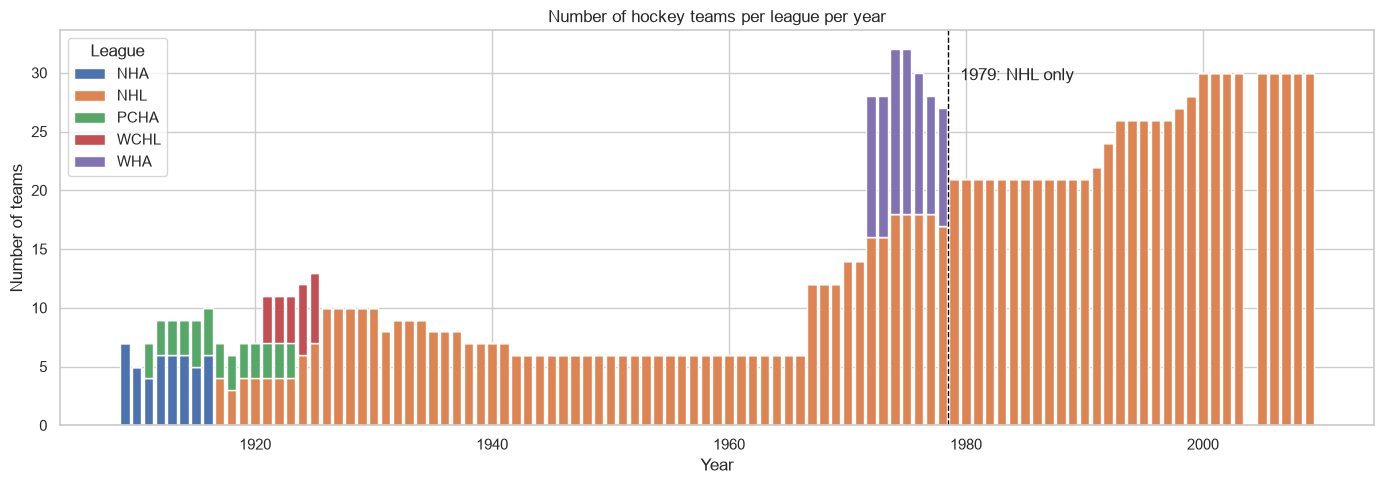

In [42]:
teams = pd.read_csv('./data/Teams.csv')
# Number of teams per league in each season
teams_per_league = (
    teams.groupby(["year", "lgID"])["franchID"]
    .nunique()
    .unstack(fill_value=0)   # rows = year, columns = league
    .sort_index()
)

display(teams_per_league)

years = teams_per_league.index.to_numpy()

fig, ax = plt.subplots(figsize=(14, 5))

# Initialize bottom for stacking
bottom = np.zeros(len(years))

# Create stacked bars: one stack segment per league
for league, counts in teams_per_league.items():
    ax.bar(years, counts.to_numpy(), bottom=bottom, width=0.8, label=league)
    bottom += counts.to_numpy()  # Update bottom for the next stack

# Mark the cutoff year we use
ax.axvline(1978.5, color="black", linestyle="--", linewidth=1)
ax.text(1979.5, bottom.max() * 0.95, "1979: NHL only", va="top")

# Add title, labels and legend
ax.set_title("Number of hockey teams per league per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of teams")
ax.legend(title="League", loc="upper left")

plt.tight_layout()
plt.show()


**Finding:** We think it is pertinent to only use data from 1979 onwards, when the NHL is the only league and there are more or less the same number of teams every year.

## Analysis of franchises that changed teams

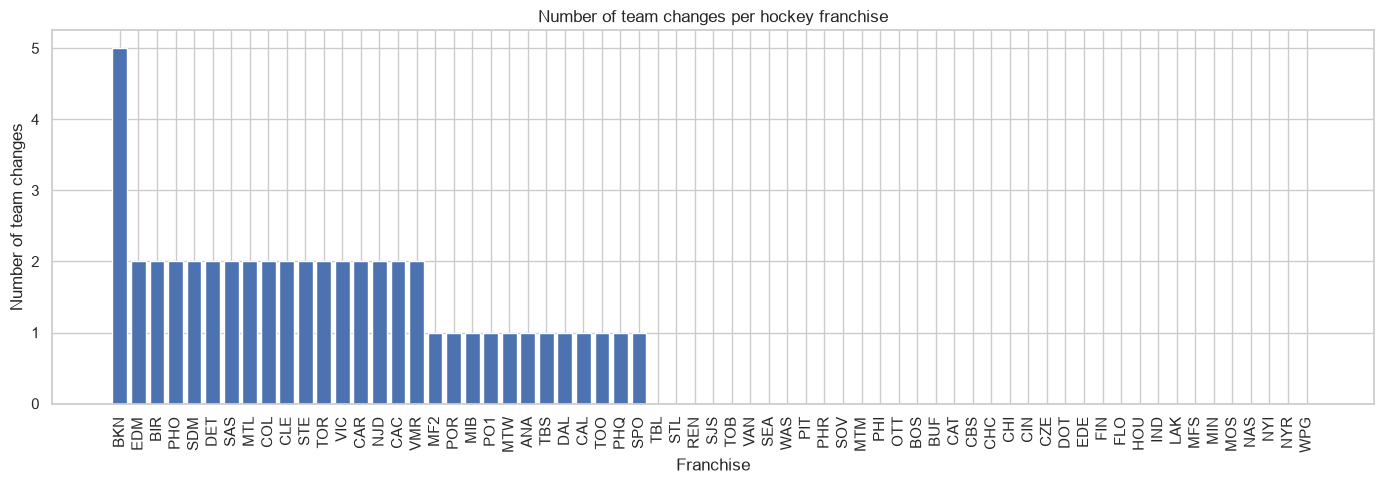

In [43]:
# Number of team ID changes per franchise (a franchise with 3 team IDs changed twice)
team_changes = (
    teams.groupby("franchID")["tmID"]
    .nunique()
    .sub(1)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(team_changes.index, team_changes.to_numpy(), width=0.8)

# Add title and labels
ax.set_title("Number of team changes per hockey franchise")
ax.set_xlabel("Franchise")
ax.set_ylabel("Number of team changes")
ax.set_yticks(range(0, team_changes.max() + 1))
ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

**Finding:** There have been franchises who have moved to different cities, so we should probably use franchID when trying to find the same team over the years

## Overall win-draw-tie records per team

,W,L,T,OTL
franchID,,,,
ANA,557,539,107.0,77.0
BIR,242,286,28.0,0.0
BKN,383,571,130.0,0.0
BOS,2761,2153,791.0,91.0
BUF,1487,1158,409.0,62.0
CAC,174,207,14.0,0.0
CAL,1359,1156,379.0,66.0
CAR,1257,1342,301.0,59.0
CAT,71,67,4.0,0.0


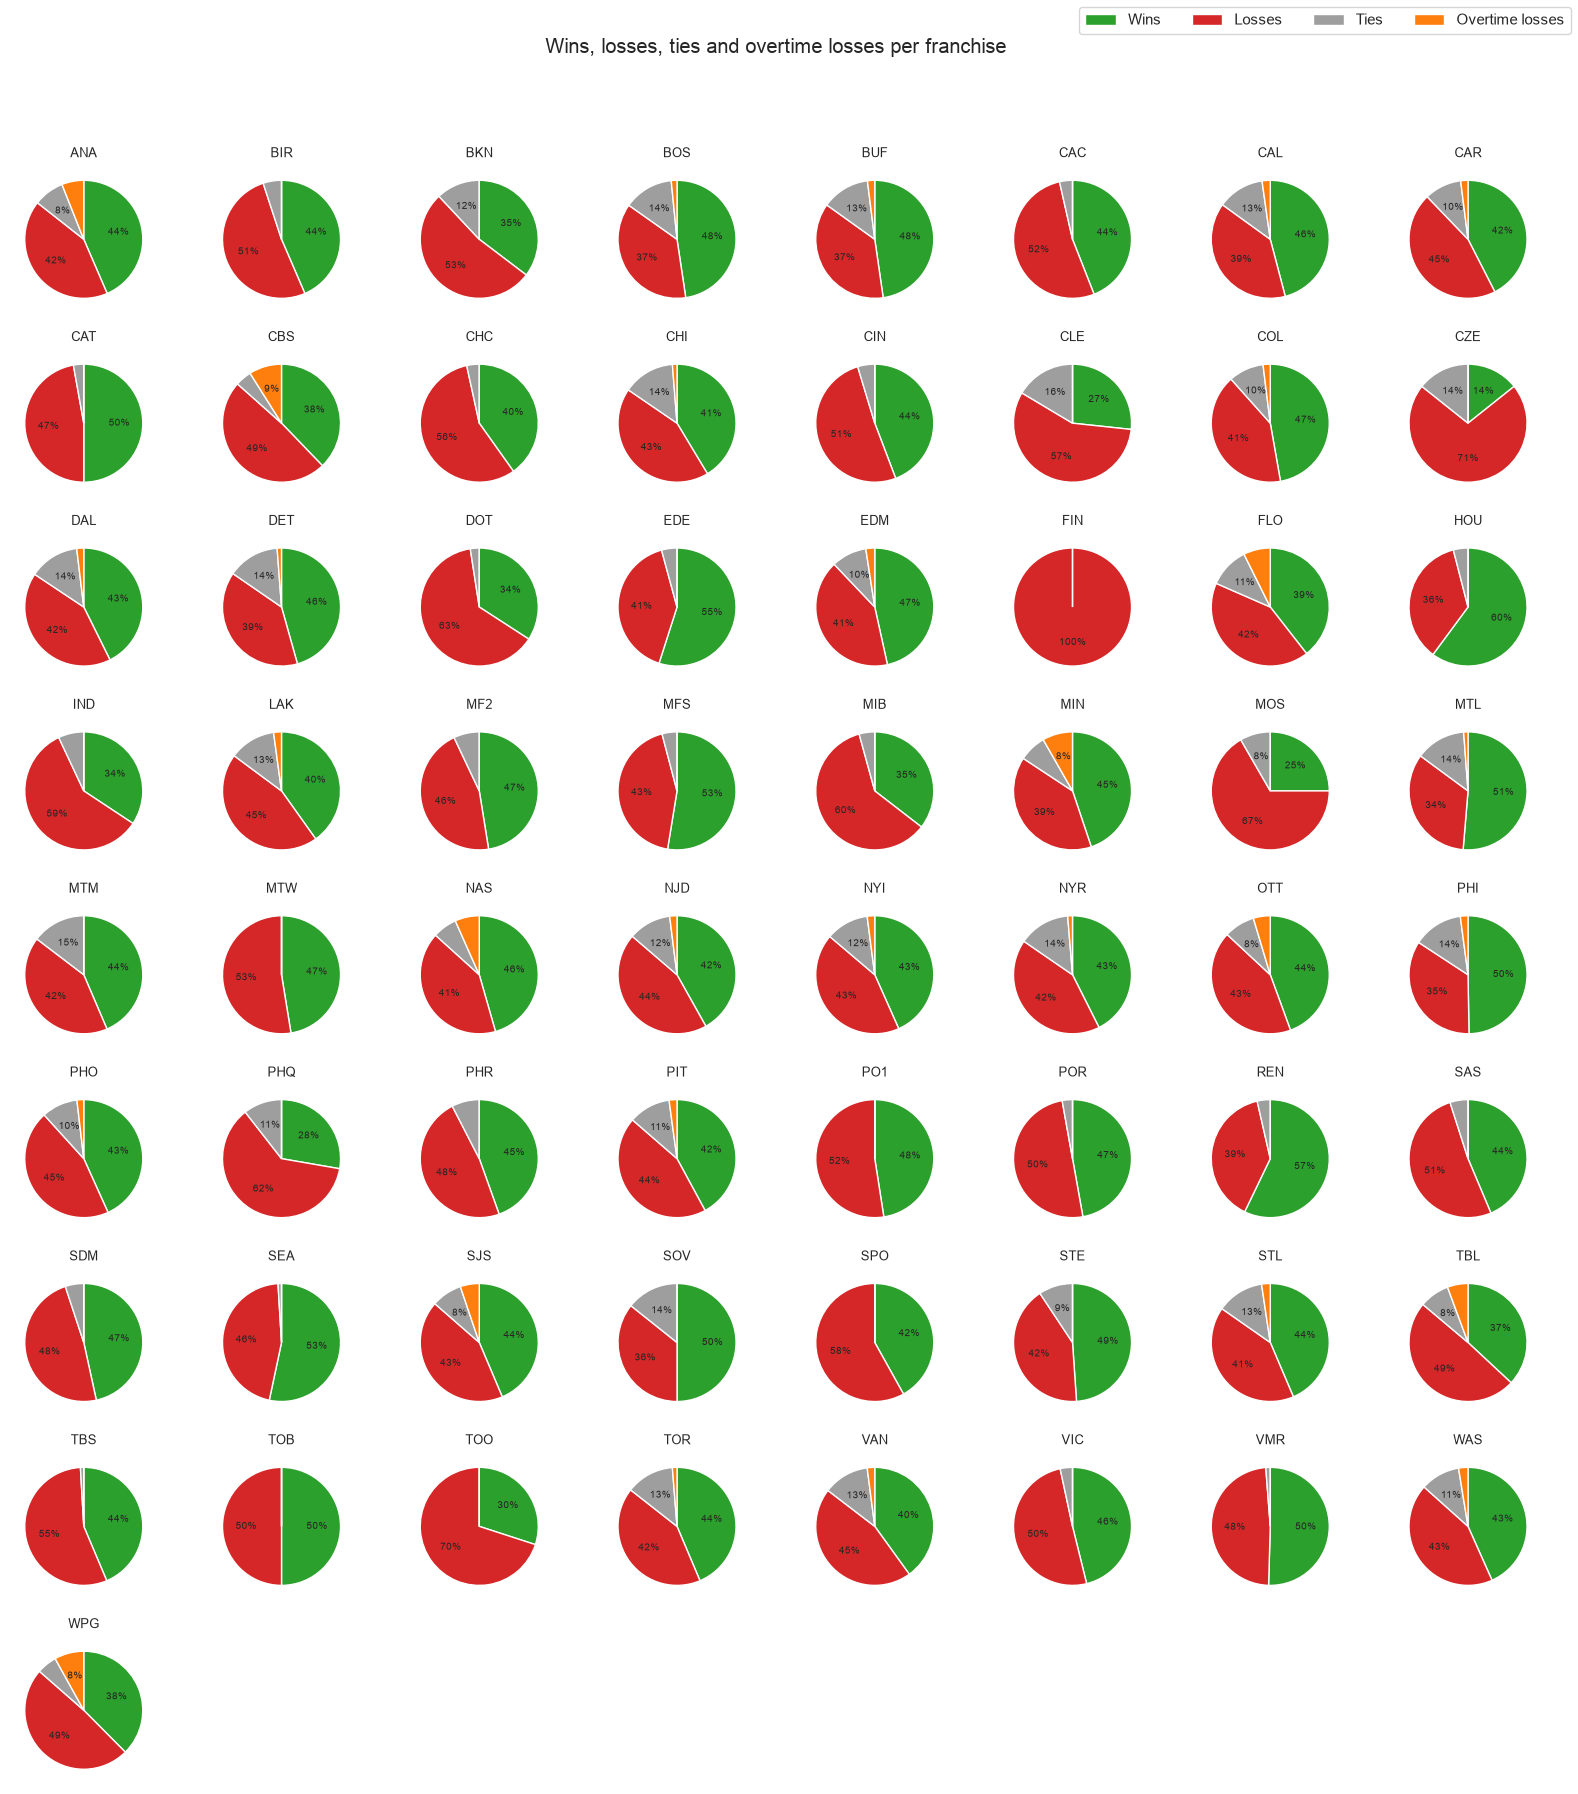

In [44]:
# Total wins, losses, ties and overtime losses per franchise
team_wins_losses_ties = (
    teams.groupby("franchID")[["W", "L", "T", "OTL"]]
    .sum()
    .sort_index()
)
display(team_wins_losses_ties)

# One small pie per franchise, laid out in a grid
n_cols = 8
n_rows = int(np.ceil(len(team_wins_losses_ties) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows))
axes = axes.flatten()

labels = ["Wins", "Losses", "Ties", "Overtime losses"]
colors = ["#2ca02c", "#d62728", "#9e9e9e", "#ff7f0e"]

# Each row of the table is one franchise: its W, L, T, OTL values are the pie slices
for ax, (franchise, record) in zip(axes, team_wins_losses_ties.iterrows()):
    ax.pie(record.to_numpy(), colors=colors, startangle=90, counterclock=False,
           autopct=lambda p: f"{p:.0f}%" if p >= 8 else "", textprops={"fontsize": 7})
    ax.set_title(franchise, fontsize=9)

# Hide the empty grid cells left after the last franchise
for ax in axes[len(team_wins_losses_ties):]:
    ax.axis("off")

fig.suptitle("Wins, losses, ties and overtime losses per franchise")
fig.legend(labels, loc="upper right", ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Finding:** Some franchises have only wins and losses, others have those and tie losses, and others all 4 kinds. Let's see if franchises that exist from 1979 onwards have more uniform records.

## Overall win-draw-tie records per team, 1979 onwards

,W,L,T,OTL
franchID,,,,
ANA,557,539,107.0,77.0
BOS,1185,866,262.0,91.0
BUF,1155,907,280.0,62.0
CAL,1126,928,284.0,66.0
CAR,976,1106,263.0,59.0
CBS,279,360,33.0,66.0
CHI,1052,1003,277.0,72.0
COL,1103,982,261.0,58.0
DAL,1125,917,298.0,64.0


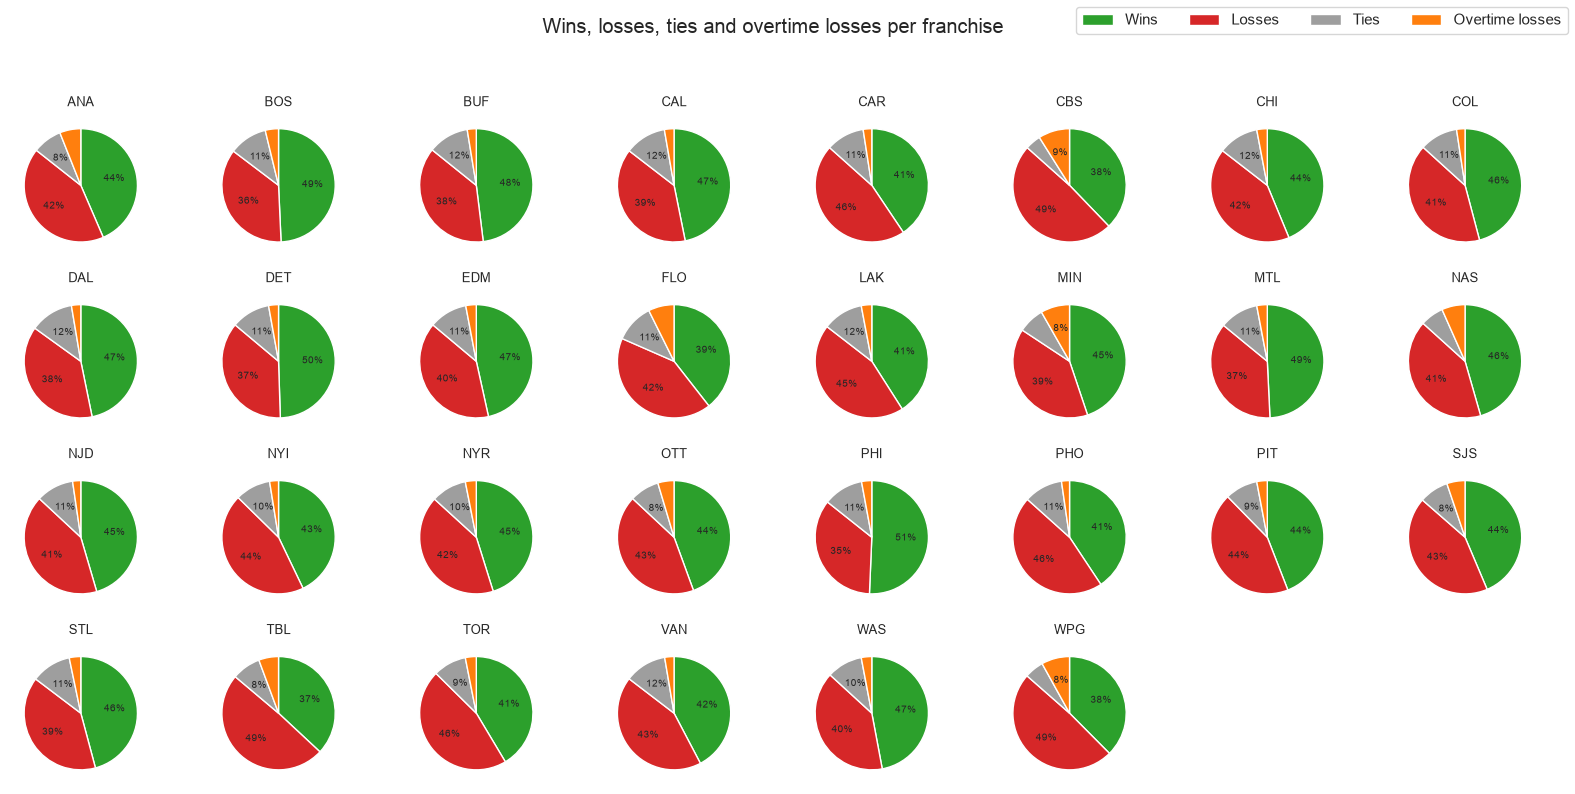

In [45]:
# Total wins, losses, ties and overtime losses per franchise
teams_1979 = teams[teams['year'] >= 1979]
team_wins_losses_ties = (
    teams_1979.groupby("franchID")[["W", "L", "T", "OTL"]]
    .sum()
    .sort_index()
)
display(team_wins_losses_ties)

# Because there are a lot of charts, we will add 8 columns so they can fit better
n_cols = 8
n_rows = int(np.ceil(len(team_wins_losses_ties) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows))
axes = axes.flatten()

labels = ["Wins", "Losses", "Ties", "Overtime losses"]
colors = ["#2ca02c", "#d62728", "#9e9e9e", "#ff7f0e"]

# Each row of the table is one franchise: its W, L, T, OTL values are the pie slices
for ax, (franchise, record) in zip(axes, team_wins_losses_ties.iterrows()):
    ax.pie(record.to_numpy(), colors=colors, startangle=90, counterclock=False,
           autopct=lambda p: f"{p:.0f}%" if p >= 8 else "", textprops={"fontsize": 7})
    ax.set_title(franchise, fontsize=9)

# Hide the empty grid cells left after the last franchise
for ax in axes[len(team_wins_losses_ties):]:
    ax.axis("off")

fig.suptitle("Wins, losses, ties and overtime losses per franchise")
fig.legend(labels, loc="upper right", ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Finding:** Now all teams have all types of wins, losses, ties and OTLs.

## Points percentage of franchises across the years

The previous two charts shows that win/loss/ties/OTL records are more consistent from 1979 onwards, so now we want to analyze the points records of teams throughout the years and see how the teams do year-on-year

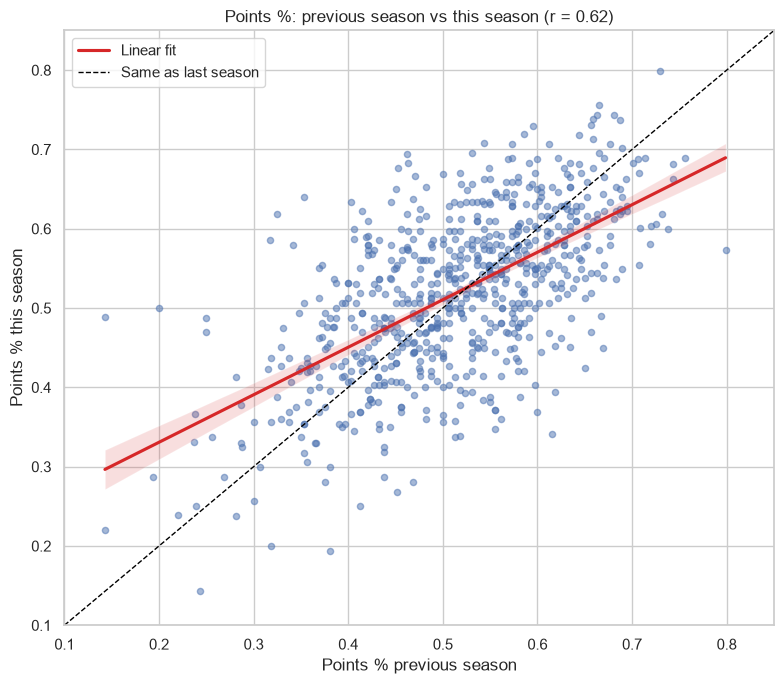

'Same as last season' baseline: mean absolute error = 0.070 points % (≈ 11.5 points in an 82-game season)


In [46]:
# Target: points % = Pts / (2 * G), so seasons of with a different number of games are comparable.
pts_df = teams_1979.copy()

pts_df["points_percentage"] = pts_df["Pts"] / (2 * pts_df["G"])

# Previous season of the same franchise (franchID, so relocated teams keep their history)
pts_df = pts_df.sort_values(["franchID", "year"])
prev = pts_df.groupby("franchID")["points_percentage"].shift(1)
pts_df["prev_points_percentage"] = prev

pairs = pts_df.dropna(subset=["prev_points_percentage"])
correlation_coefficient = pairs["prev_points_percentage"].corr(pairs["points_percentage"])
mean_absolute_error = (pairs["prev_points_percentage"] - pairs["points_percentage"]).abs().mean()

fig, ax = plt.subplots(figsize=(8, 7))
sns.regplot(data=pairs, x="prev_points_percentage", y="points_percentage", ax=ax,
            scatter_kws={"s": 20, "alpha": 0.5}, line_kws={"color": "#d62728", "label": "Linear fit"})

# Reference line: "same points % as last season"
lims = [0.1, 0.85]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="Same as last season")
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title(f"Points %: previous season vs this season (r = {correlation_coefficient:.2f})")
ax.set_xlabel("Points % previous season")
ax.set_ylabel("Points % this season")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"'Same as last season' baseline: mean absolute error = {mean_absolute_error:.3f} points % "
      f"(≈ {mean_absolute_error * 2 * 82:.1f} points in an 82-game season)")

**Findings:** Last season's points can predict the next season's points well. Note that teams that do better one season, do a bit worse in the next and viceversa.